## Import

In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

## Setup

In [2]:
SEED = 42
np.random.seed(SEED)
os.makedirs("weights_V3_0", exist_ok=True)
print("lightgbm:", lgb.__version__)

lightgbm: 4.7.0


In [3]:
# ---- 1. LOAD DATA (identical to V1.1) ----
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
print("cleaned:", df.shape, "| Response rate:", round(df["Response"].mean(), 4))

CLF_NUMERIC = [
    "AcceptedCmp5", "AcceptedCmp3", "MntWines", "MntMeatProducts",
    "NumCatalogPurchases", "Recency", "Customer_Tenure_Days", "MntGoldProds",
    "Income", "MntFruits",
    "AcceptedCmp1", "AcceptedCmp2", "NumWebPurchases", "MntSweetProducts",
    "MntFishProducts", "NumStorePurchases", "Age",
]
X_num = df[CLF_NUMERIC].copy()
X_cat = pd.get_dummies(df[["Marital_Status"]], dtype=float)
X_full = pd.concat([X_num, X_cat], axis=1)
FEATURE_COLS = list(X_full.columns)
y_full = df["Response"].astype(float).values
print(f"features: {len(CLF_NUMERIC)} numeric + {X_cat.shape[1]} dummies = {len(FEATURE_COLS)} dims")

cleaned: (2236, 28) | Response rate: 0.1494
features: 17 numeric + 5 dummies = 22 dims


## Dataloader

In [4]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X_full.values, y_full, test_size=0.20, random_state=SEED, stratify=y_full)
inc_idx = FEATURE_COLS.index("Income")
train_median = np.nanmedian(X_temp[:, inc_idx])
for arr in (X_temp, X_test):
    arr[:, inc_idx] = np.where(np.isnan(arr[:, inc_idx]), train_median, arr[:, inc_idx])
print(f"train {X_temp.shape} test {X_test.shape} | test pos rate {y_test.mean():.3f} | median fill {train_median:.0f}")

train (1788, 22) test (448, 22) | test pos rate 0.150 | median fill 51651


In [5]:
pos = (y_temp == 1).sum(); neg = (y_temp == 0).sum()
scale_pos_weight = neg / pos
print(f"scale_pos_weight: {scale_pos_weight:.3f}")

scale_pos_weight: 5.697


In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_temp, y_temp, test_size=0.10, random_state=SEED, stratify=y_temp)

## Model

In [7]:
clf = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    random_state=SEED,
    verbosity=-1,
)

## Training

In [8]:
clf.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    eval_names=["train", "valid"],
    eval_metric="binary_logloss",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
print(f"best_iteration: {clf.best_iteration_}")

/Users/waroonragwongsiri/Playground/IntroMLHomework/Data/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best_iteration: 73


In [9]:
history = pd.DataFrame({
    "round": range(1, len(clf.evals_result_["train"]["binary_logloss"]) + 1),
    "train_metric": clf.evals_result_["train"]["binary_logloss"],
    "val_metric": clf.evals_result_["valid"]["binary_logloss"],
})
history.to_csv("weights_V3_0/classification_lightgbm_history.csv", index=False)
print(f"history: {len(history)} rounds -> weights_V3_0/classification_lightgbm_history.csv")

history: 123 rounds -> weights_V3_0/classification_lightgbm_history.csv


## Evaluation

In [10]:
prob = clf.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)

metrics = {
    "test_loss_BCE": round(float(log_loss(y_test, prob)), 4),
    "accuracy": round(float(accuracy_score(y_test, pred)), 4),
    "precision": round(float(precision_score(y_test, pred, zero_division=0)), 4),
    "recall": round(float(recall_score(y_test, pred, zero_division=0)), 4),
    "f1": round(float(f1_score(y_test, pred, zero_division=0)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, prob)), 4),
    "n_test": int(len(y_test)), "seed": SEED, "best_iteration": int(clf.best_iteration_),
}
print(json.dumps(metrics, indent=2))
with open("weights_V3_0/classification_lightgbm_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
for i in range(5):
    print(f"  prob={prob[i]:.3f} pred={pred[i]} true={int(y_test[i])}")

{
  "test_loss_BCE": 0.2967,
  "accuracy": 0.8728,
  "precision": 0.5658,
  "recall": 0.6418,
  "f1": 0.6014,
  "roc_auc": 0.8898,
  "n_test": 448,
  "seed": 42,
  "best_iteration": 73
}
  prob=0.013 pred=0 true=0
  prob=0.006 pred=0 true=0
  prob=0.013 pred=0 true=0
  prob=0.147 pred=0 true=0
  prob=0.009 pred=0 true=0


saved to weights_V3_0/


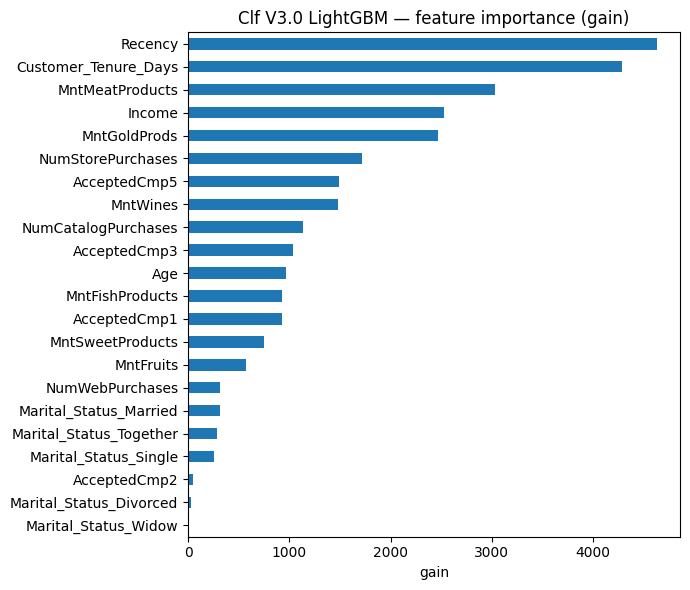

Recency                 4625.764803
Customer_Tenure_Days    4284.163679
MntMeatProducts         3032.811158
Income                  2528.345216
MntGoldProds            2470.635755
dtype: float64


In [11]:
clf.booster_.save_model("weights_V3_0/classification_lightgbm.txt")
print("saved to weights_V3_0/")

imp = pd.Series(clf.booster_.feature_importance(importance_type="gain"), index=FEATURE_COLS).sort_values()
plt.figure(figsize=(7, 6))
imp.plot(kind="barh")
plt.xlabel("gain"); plt.title("Clf V3.0 LightGBM — feature importance (gain)")
plt.tight_layout()
plt.savefig("media/featimp_clf_V3_0.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).head(5))